In [1]:
pip install pandas matplotlib statsmodels openpyxl

Jumlah data: 75 minggu (2026-08-30 s/d 2028-01-30)


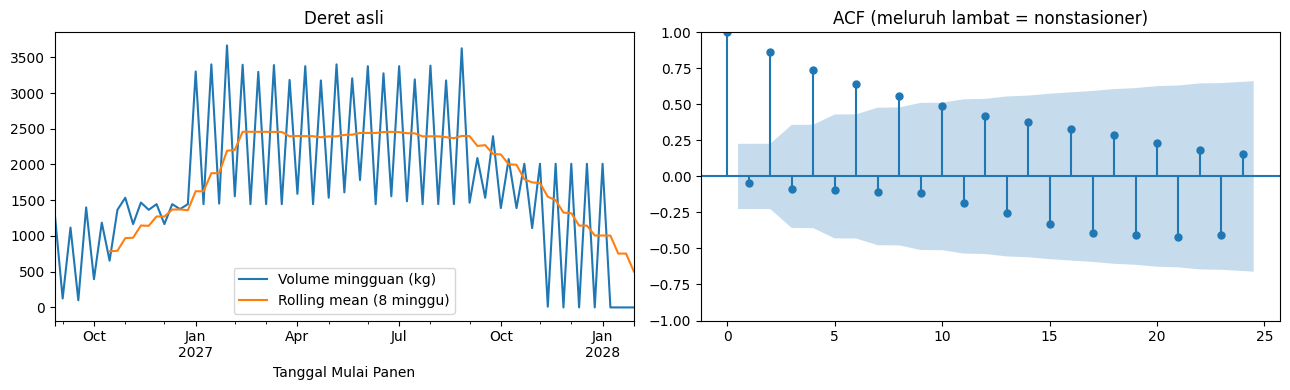

ADF p-value = 0.9121 -> NONSTASIONER


In [2]:
"""
Langkah 1: memastikan data TIDAK STASIONER
Sheet : 4_Jadwal_Tanam_Panen
Deret : volume target panen (kg) dari batch yang mulai panen, per minggu
Install: pip install pandas matplotlib statsmodels openpyxl
"""
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

warnings.filterwarnings("ignore")
FILE = "Rancangan_Keberlanjutan_Rantai_Pasok_Pasar_Tani.xlsx"
ALPHA = 0.05

# 1. Bangun deret waktu (hanya baris bersatuan kg)
df = pd.read_excel(FILE, sheet_name="4_Jadwal_Tanam_Panen")
df["Tanggal Mulai Panen"] = pd.to_datetime(df["Tanggal Mulai Panen"])
df["kg"] = (df["Target Panen Harian"].astype(str).str.lower()
              .str.extract(r"(\d+[.,]?\d*)\s*kg")[0]
              .str.replace(",", ".").astype(float))
y = (df.dropna(subset=["kg"]).set_index("Tanggal Mulai Panen")["kg"]
       .resample("W").sum())
print(f"Jumlah data: {len(y)} minggu ({y.index.min().date()} s/d {y.index.max().date()})")

# 2. Plot: deret asli + rolling mean + ACF
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
y.plot(ax=ax[0], label="Volume mingguan (kg)")
y.rolling(8).mean().plot(ax=ax[0], label="Rolling mean (8 minggu)")
ax[0].set_title("Deret asli"); ax[0].legend()
plot_acf(y, lags=24, ax=ax[1]); ax[1].set_title("ACF (meluruh lambat = nonstasioner)")
plt.tight_layout(); plt.savefig("cek_stasioneritas.png", dpi=150); plt.show()

# 3. Uji ADF (H0: nonstasioner; p >= 0,05 -> nonstasioner)
adf_p = adfuller(y, autolag="AIC")[1]
print(f"ADF p-value = {adf_p:.4f} -> {'stasioner' if adf_p < ALPHA else 'NONSTASIONER'}")

Latih: 60 minggu (2026-08-30 s/d 2027-10-17)
Uji  : 15 minggu (2027-10-24 s/d 2028-01-30)

ADF data latih asli          : p = 0.2495
ADF setelah diferensiasi d=1,D=1: p = 0.0000 -> STASIONER


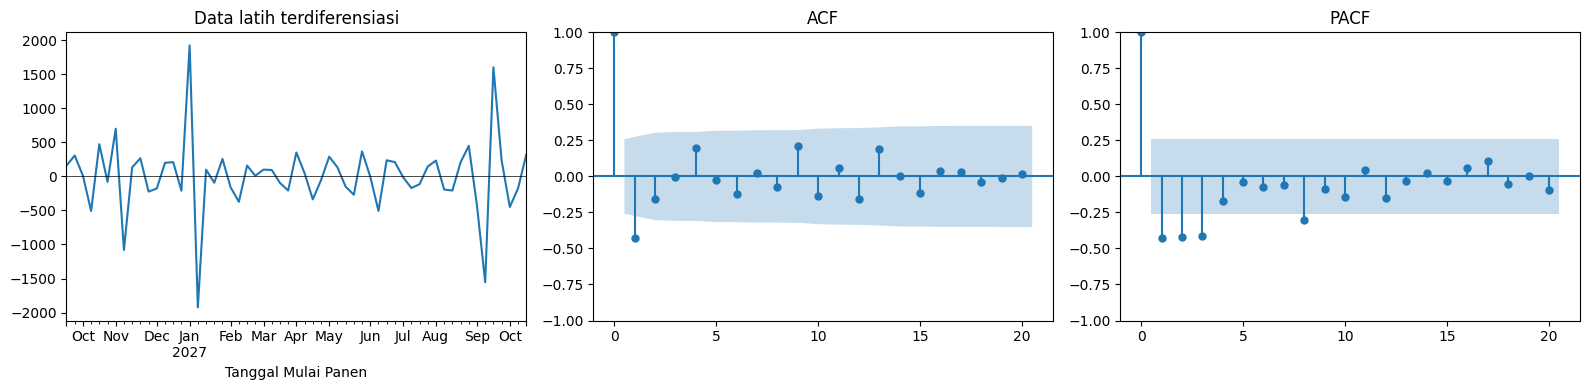


5 kandidat terbaik (urut AIC):
       order      seasonal     AIC     BIC
0  (0, 1, 1)  (1, 1, 1, 2)  789.91  797.79
1  (0, 1, 1)  (0, 1, 1, 2)  790.17  796.08
2  (1, 1, 1)  (1, 1, 1, 2)  791.33  801.18
3  (1, 1, 1)  (0, 1, 1, 2)  791.52  799.41
4  (2, 1, 1)  (0, 1, 1, 2)  791.85  801.70

Orde terpilih (AIC terkecil): SARIMA(0, 1, 1)(1, 1, 1, 2)


In [3]:
"""
Langkah 2: pisah data latih/uji -> diferensiasi -> pilih orde SARIMA
Semua keputusan (diferensiasi, orde) HANYA memakai data latih agar tidak ada kebocoran data uji.
Install: pip install pandas matplotlib statsmodels openpyxl
"""
import itertools
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
FILE = "Rancangan_Keberlanjutan_Rantai_Pasok_Pasar_Tani.xlsx"
S = 2             # periode musiman (2 minggu)
TEST_WEEKS = 15   # sekitar 20% dari 75 minggu
ALPHA = 0.05

# 1. Bangun deret mingguan (sama seperti langkah 1)
df = pd.read_excel(FILE, sheet_name="4_Jadwal_Tanam_Panen")
df["Tanggal Mulai Panen"] = pd.to_datetime(df["Tanggal Mulai Panen"])
df["kg"] = (df["Target Panen Harian"].astype(str).str.lower()
              .str.extract(r"(\d+[.,]?\d*)\s*kg")[0]
              .str.replace(",", ".").astype(float))
y = df.dropna(subset=["kg"]).set_index("Tanggal Mulai Panen")["kg"].resample("W").sum()

# 2. Pisah data secara berurutan (tanpa diacak)
train, test = y.iloc[:-TEST_WEEKS], y.iloc[-TEST_WEEKS:]
print(f"Latih: {len(train)} minggu ({train.index[0].date()} s/d {train.index[-1].date()})")
print(f"Uji  : {len(test)} minggu ({test.index[0].date()} s/d {test.index[-1].date()})")
y.to_csv("deret_mingguan_kg.csv")          # disimpan untuk langkah berikutnya

# 3. Diferensiasi pada data latih: Z_t = (1-B)(1-B^S) Y_t
def adf_p(x):
    return adfuller(x.dropna(), autolag="AIC")[1]

z = train.diff(S).diff(1).dropna()
print(f"\nADF data latih asli          : p = {adf_p(train):.4f}")
print(f"ADF setelah diferensiasi d=1,D=1: p = {adf_p(z):.4f} -> "
      f"{'STASIONER' if adf_p(z) < ALPHA else 'masih nonstasioner'}")

# 4. Plot data terdiferensiasi + ACF/PACF (untuk melihat kandidat orde)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
z.plot(ax=ax[0]); ax[0].axhline(0, color="k", lw=.5); ax[0].set_title("Data latih terdiferensiasi")
plot_acf(z, lags=20, ax=ax[1]); ax[1].set_title("ACF")
plot_pacf(z, lags=20, ax=ax[2], method="ywm"); ax[2].set_title("PACF")
plt.tight_layout(); plt.savefig("langkah2_diferensiasi.png", dpi=150); plt.show()

# 5. Pilih orde SARIMA(p,1,q)(P,1,Q)_S dengan AIC/BIC (data latih saja)
hasil = []
for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
    try:
        m = SARIMAX(train, order=(p, 1, q), seasonal_order=(P, 1, Q, S),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        hasil.append({"order": (p, 1, q), "seasonal": (P, 1, Q, S), "AIC": m.aic, "BIC": m.bic})
    except Exception:
        pass

tabel = pd.DataFrame(hasil).sort_values("AIC").reset_index(drop=True)
print("\n5 kandidat terbaik (urut AIC):")
print(tabel.head(5).round(2).to_string())
print(f"\nOrde terpilih (AIC terkecil): SARIMA{tabel.loc[0,'order']}{tabel.loc[0,'seasonal']}")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.9303      0.156     -5.980      0.000      -1.235      -0.625
ar.S.L2       -0.7367      0.469     -1.572      0.116      -1.655       0.182
ma.S.L2        0.5455      0.675      0.808      0.419      -0.777       1.868
sigma2      1.472e+05   1.66e+04      8.863      0.000    1.15e+05     1.8e+05

Ljung-Box residual (lag 10): p = 0.7970 -> residual white noise (model memadai)


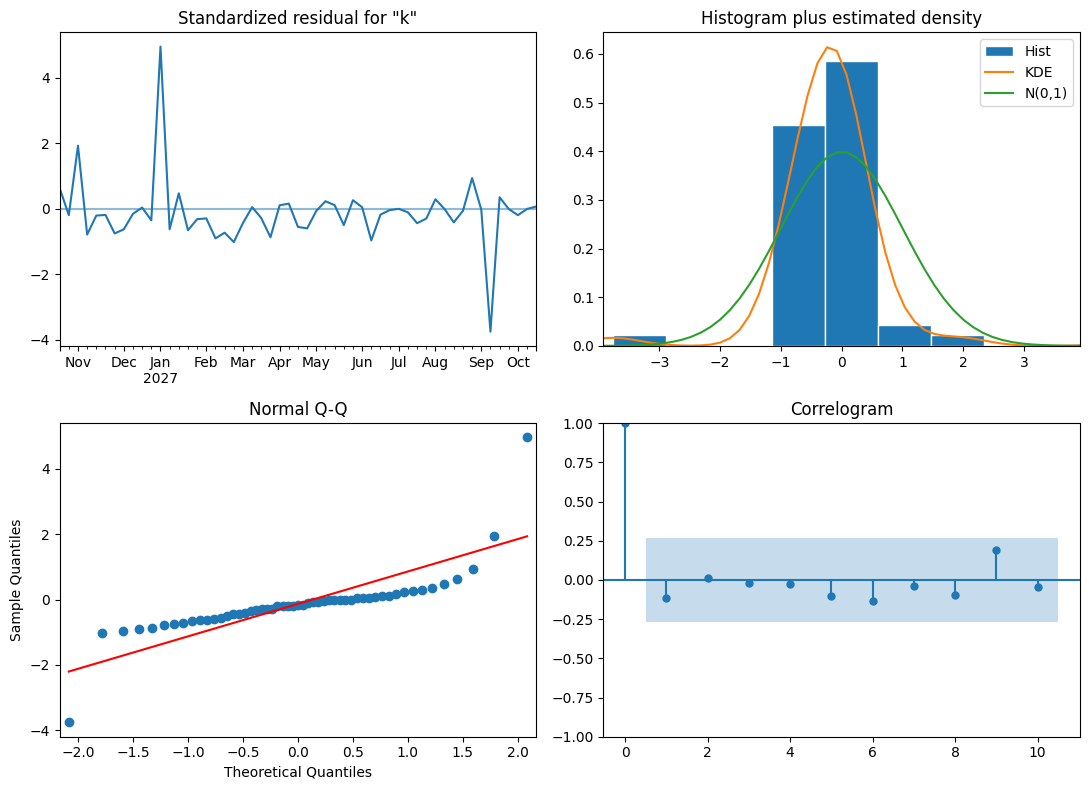


Metrik pada data uji (kg):
                 MAE     RMSE  MASE
Naif musiman  877.20  1163.01  4.17
SARIMA        745.83   979.45  3.55


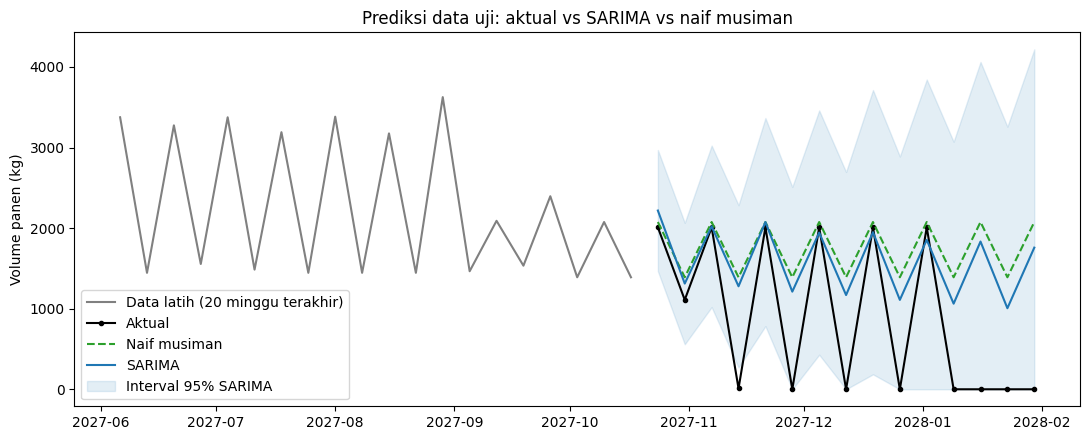

In [4]:
"""
Langkah 3: estimasi SARIMA(0,1,1)(1,1,1)_2 pada data latih, cek residual,
buat model naif musiman (tolok ukur), lalu ramal 15 minggu data uji.
Membutuhkan 'deret_mingguan_kg.csv' dari langkah 2.
Install: pip install pandas numpy matplotlib scipy statsmodels
"""
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
S, TEST_WEEKS, ALPHA = 2, 15, 0.05
ORDER, SEAS = (0, 1, 1), (1, 1, 1, S)        # hasil langkah 2

# 1. Muat deret dan pisah latih/uji (sama seperti langkah 2)
y = pd.read_csv("deret_mingguan_kg.csv", index_col=0, parse_dates=True).iloc[:, 0]
train, test = y.iloc[:-TEST_WEEKS], y.iloc[-TEST_WEEKS:]

# 2. Estimasi SARIMA pada data latih
res = SARIMAX(train, order=ORDER, seasonal_order=SEAS,
              enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
print(res.summary().tables[1])

# 3. Diagnosis residual (abaikan d + D*S = 3 residual awal)
resid = res.resid.iloc[ORDER[1] + SEAS[1] * S:]
p_lb = float(acorr_ljungbox(resid, lags=[10], return_df=True)["lb_pvalue"].iloc[0])
print(f"\nLjung-Box residual (lag 10): p = {p_lb:.4f} -> "
      f"{'residual white noise (model memadai)' if p_lb > ALPHA else 'masih ada autokorelasi (coba kandidat orde lain)'}")
res.plot_diagnostics(figsize=(11, 8)); plt.tight_layout()
plt.savefig("langkah3_diagnostik.png", dpi=150); plt.show()

# 4. Model naif musiman: ulangi nilai S minggu terakhir data latih
naif = pd.Series(np.tile(train.iloc[-S:].values, TEST_WEEKS // S + 1)[:TEST_WEEKS], index=test.index)

# 5. Ramalan SARIMA 15 minggu sekaligus dari akhir data latih (multi-step langsung dari satu titik asal)
fc = res.get_forecast(TEST_WEEKS)
sarima = fc.predicted_mean.clip(lower=0)      # volume panen tidak boleh negatif
ci = fc.conf_int(alpha=ALPHA).clip(lower=0)

# 6. Metrik awal (MASE: penyebut = galat naif musiman pada data latih)
def metrik(aktual, pred):
    e = aktual - pred
    return {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()),
            "MASE": e.abs().mean() / train.diff(S).abs().dropna().mean()}

print("\nMetrik pada data uji (kg):")
print(pd.DataFrame({"Naif musiman": metrik(test, naif),
                    "SARIMA": metrik(test, sarima)}).T.round(2))

# 7. Grafik aktual vs prediksi
plt.figure(figsize=(11, 4.5))
plt.plot(train.index[-20:], train.iloc[-20:], color="gray", label="Data latih (20 minggu terakhir)")
plt.plot(test, color="black", marker="o", ms=3, label="Aktual")
plt.plot(naif, "--", color="tab:green", label="Naif musiman")
plt.plot(sarima, color="tab:blue", label="SARIMA")
plt.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="tab:blue", alpha=.12, label="Interval 95% SARIMA")
plt.ylabel("Volume panen (kg)"); plt.legend(); plt.title("Prediksi data uji: aktual vs SARIMA vs naif musiman")
plt.tight_layout(); plt.savefig("langkah3_prediksi.png", dpi=150); plt.show()

# 8. Simpan untuk langkah 4-5
pd.DataFrame({"aktual": test, "naif_musiman": naif, "sarima": sarima}).to_csv("prediksi_langkah3.csv")